# Complete Exploratory Analysis and Model Demonstration
**Project:** Bank Marketing Subscription Prediction and Campaign Optimization

## 1. Problem definition

**Business question:** Can information available before a marketing call help estimate whether a customer will subscribe to a term deposit?

- Task: binary classification.
- Target: `y` (`yes` / `no`).
- Intended user: campaign analyst prioritizing outreach for review.
- Prediction-time constraint: exclude `duration`, because call duration is only known after the call.
- This is predictive association, not causal inference or a clinically/financially validated decision system.

## 2. Imports and reproducibility

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, mannwhitneyu
from ucimlrepo import fetch_ucirepo

RANDOM_STATE = 42
ROOT = Path.cwd()
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

## 3. Load the official UCI dataset

In [2]:
dataset = fetch_ucirepo(id=222)
X_raw = dataset.data.features.copy()
y_raw = dataset.data.targets.iloc[:, 0].copy()
df = X_raw.copy()
df["y"] = y_raw.astype(str).str.strip().str.lower().values
if "day_of_week" in df.columns:
    df = df.rename(columns={"day_of_week": "day"})
print("Dataset shape:", df.shape)
display(df.head())
display(df.sample(5, random_state=RANDOM_STATE))

Dataset shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
3776,40,blue-collar,married,secondary,no,580,yes,no,NaN,16,may,192,1,-1,0,NaN,no
9928,47,services,single,secondary,no,3644,no,no,NaN,9,jun,83,2,-1,0,NaN,no
33409,25,student,single,tertiary,no,538,yes,no,cellular,20,apr,226,1,-1,0,NaN,no
31885,42,management,married,tertiary,no,1773,no,no,cellular,9,apr,311,1,336,1,failure,no
15738,56,management,married,tertiary,no,217,no,yes,cellular,21,jul,121,2,-1,0,NaN,no


**Analysis prompt:** Record the exact row and column count shown above. The UCI
`bank-full` release is documented as 45,211 records, 16 predictors and one target.
Explain that `y` is the labelled outcome required for supervised classification.

## 4. Dataset structure and data dictionary profile

In [3]:
profile = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "unique_count": df.nunique(dropna=False)
})
display(profile)
display(df.describe(include="all").T)

,dtype,missing_count,unique_count
age,int64,0,77
job,str,288,12
marital,str,0,3
education,str,1857,4
default,str,0,2
balance,int64,0,7168
housing,str,0,2
loan,str,0,2
contact,str,13020,3
day,int64,0,31


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,45211.0,NaN,NaN,NaN,40.93621,10.618762,18.0,33.0,39.0,48.0,95.0
job,44923,11,blue-collar,9732,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,45211,3,married,27214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,43354,3,secondary,23202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,45211,2,no,44396,NaN,NaN,NaN,NaN,NaN,NaN,NaN
balance,45211.0,NaN,NaN,NaN,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
housing,45211,2,yes,25130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,45211,2,no,37967,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,32191,2,cellular,29285,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day,45211.0,NaN,NaN,NaN,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0


**Analysis prompt:** Identify numeric and categorical columns from the table.
Explain at least five variables using the data dictionary in
`docs/STEP_BY_STEP_TUTORIAL.md`. Distinguish the target from predictors.

## 5. Data quality: missing values, duplicates and unknown categories

In [4]:
duplicate_count = int(df.duplicated().sum())
missing_summary = df.isna().sum().sort_values(ascending=False)
unknown_summary = {
    c: int((df[c].astype(str).str.lower() == "unknown").sum())
    for c in df.select_dtypes(include="object").columns if c != "y"
}
print("Exact duplicate rows:", duplicate_count)
display(missing_summary.to_frame("missing_count"))
print("Literal 'unknown' category counts:")
display(pd.Series(unknown_summary, name="unknown_count").to_frame())

Exact duplicate rows: 0


C:\Users\MACHERLA CHAITANYA\AppData\Local\Temp\ipykernel_12252\2900707419.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for c in df.select_dtypes(include="object").columns if c != "y"


,missing_count
poutcome,36959
contact,13020
education,1857
job,288
age,0
default,0
balance,0
housing,0
marital,0
loan,0


Literal 'unknown' category counts:


,unknown_count
job,0
marital,0
education,0
default,0
housing,0
loan,0
contact,0
month,0
poutcome,0


**Analysis prompt:** State the observed duplicate and missing-value counts.
`unknown` is a recorded category, not automatically a null. Explain how your
pipeline imputes actual missing values while retaining `unknown`.

## 6. Cleaning decision and outlier inspection

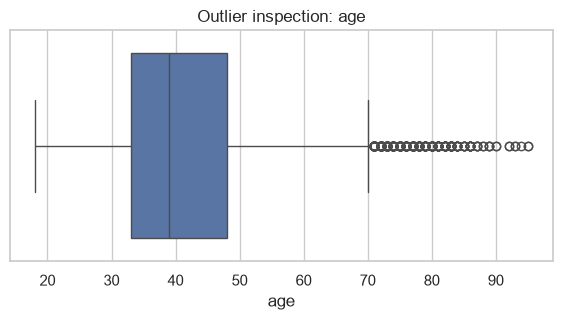

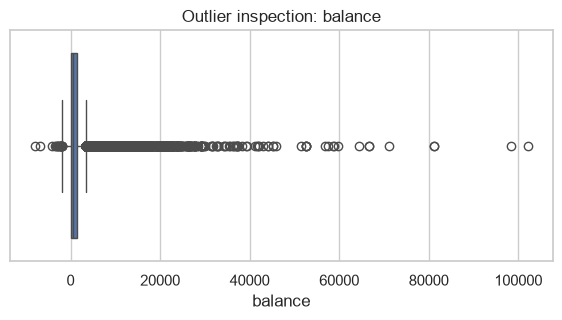

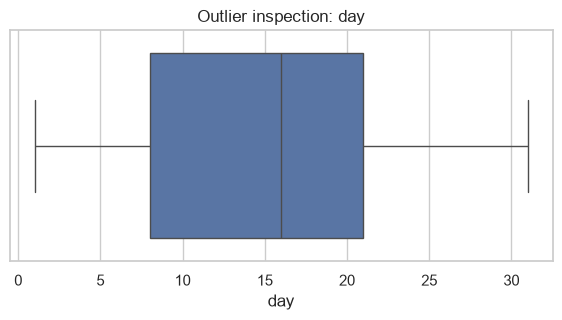

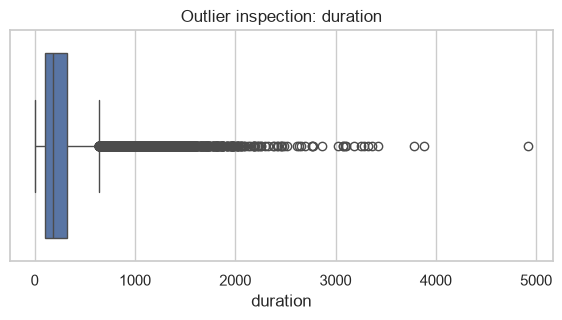

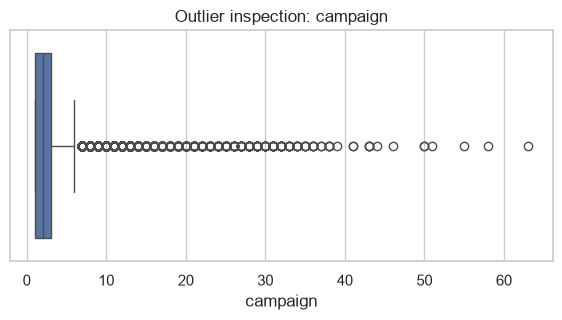

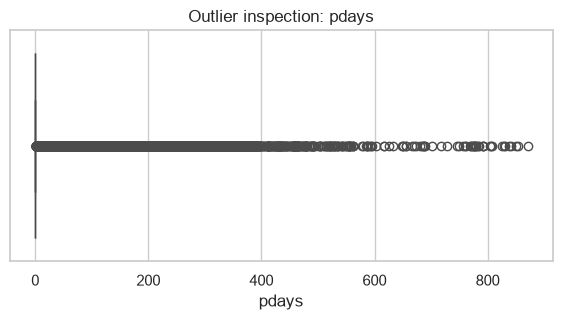

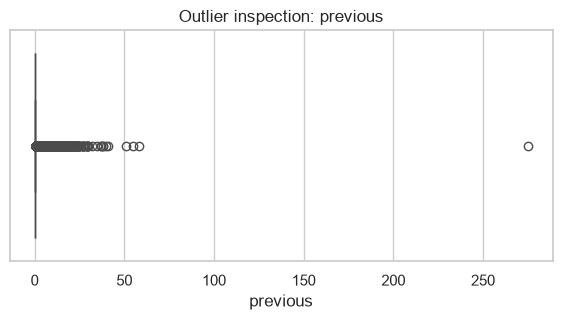

In [5]:
df_clean = df.drop_duplicates().copy()
numeric_cols = df_clean.select_dtypes(include=np.number).columns.tolist()
for col in numeric_cols:
    fig, ax = plt.subplots(figsize=(7, 3))
    sns.boxplot(data=df_clean, x=col, ax=ax)
    ax.set_title(f"Outlier inspection: {col}")
    plt.show()

**Analysis prompt:** Identify variables with skew or extreme values from your
plots. Explain why unusual but plausible balances/contact counts should not be
automatically deleted. Explain `pdays = -1` as a sentinel for no previous contact.

## 7. Target distribution and class imbalance

,count,percentage
y,,
no,39922,88.3
yes,5289,11.7


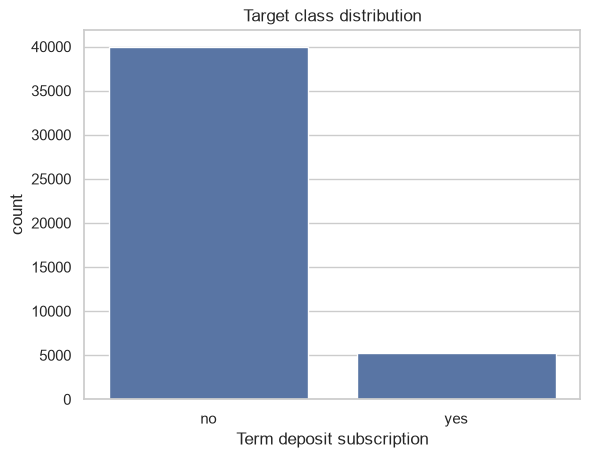

In [6]:
target_counts = df_clean["y"].value_counts()
target_pct = df_clean["y"].value_counts(normalize=True).mul(100).round(2)
display(pd.DataFrame({"count": target_counts, "percentage": target_pct}))
sns.countplot(data=df_clean, x="y")
plt.title("Target class distribution")
plt.xlabel("Term deposit subscription")
plt.show()

**Analysis prompt:** Report the actual yes/no counts and percentages. Explain why
a majority-class predictor may have high accuracy but poor usefulness for
identifying subscribers. This motivates stratification and minority-class metrics.

## 8. Univariate EDA

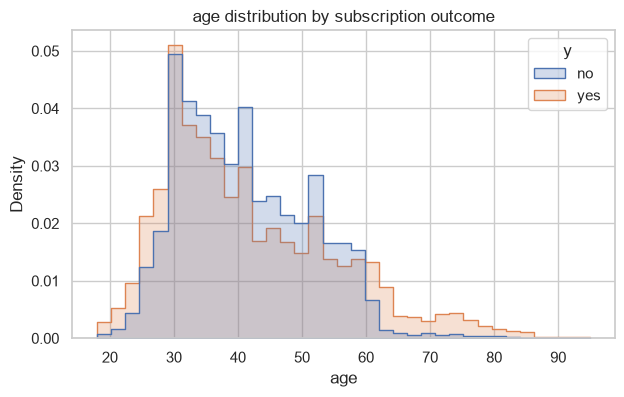

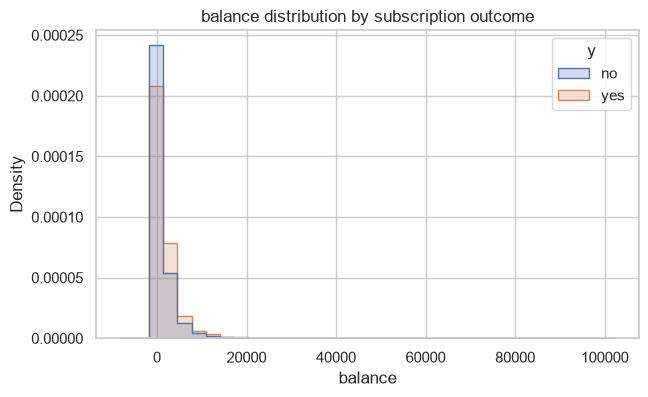

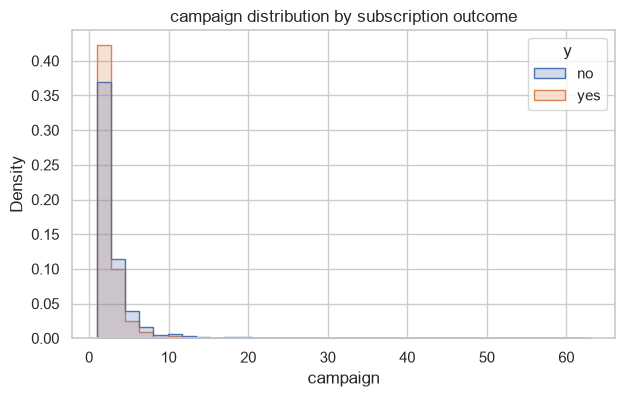

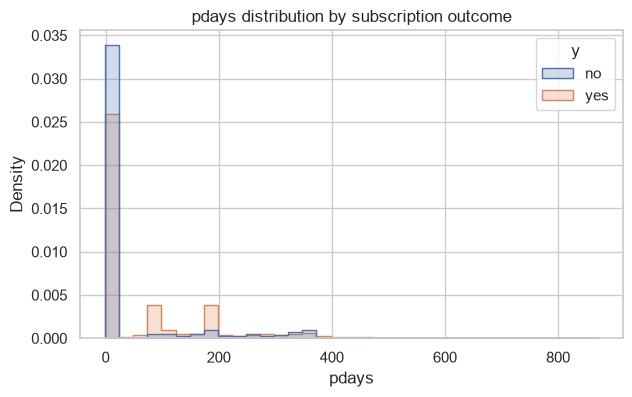

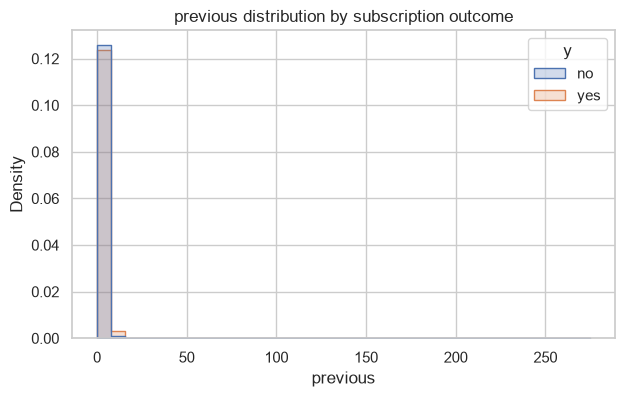

In [7]:
for col in [c for c in ["age", "balance", "campaign", "pdays", "previous"] if c in df_clean.columns]:
    plt.figure(figsize=(7, 4))
    sns.histplot(data=df_clean, x=col, hue="y", bins=35,
                 element="step", stat="density", common_norm=False)
    plt.title(f"{col} distribution by subscription outcome")
    plt.show()

**Analysis prompt:** For each variable, describe distribution shape, spread,
skewness and visible differences between target groups. Only report patterns
actually visible in your own plots.

## 9. Bivariate EDA: categorical features against target

y,no,yes
job,,
student,71.3,28.7
retired,77.2,22.8
unemployed,84.5,15.5
management,86.2,13.8
admin.,87.8,12.2
self-employed,88.2,11.8
technician,88.9,11.1
services,91.1,8.9
housemaid,91.2,8.8


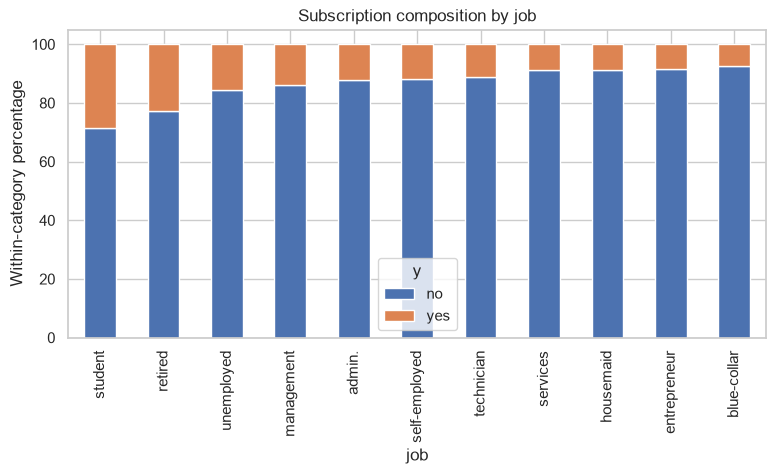

y,no,yes
education,,
tertiary,85.0,15.0
secondary,89.4,10.6
primary,91.4,8.6


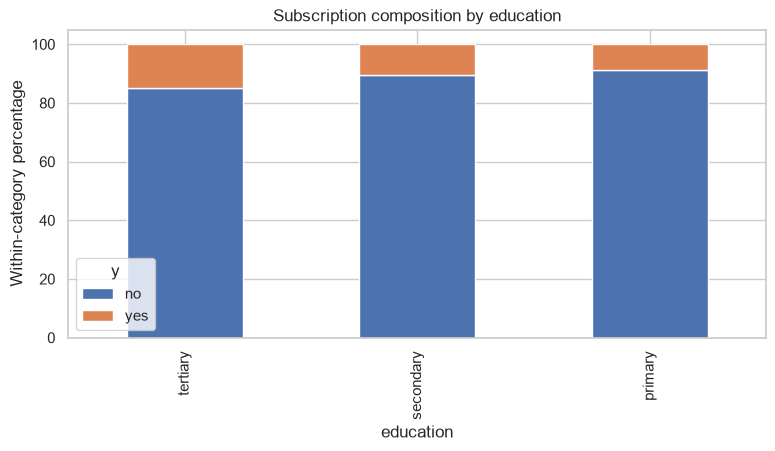

y,no,yes
housing,,
no,83.3,16.7
yes,92.3,7.7


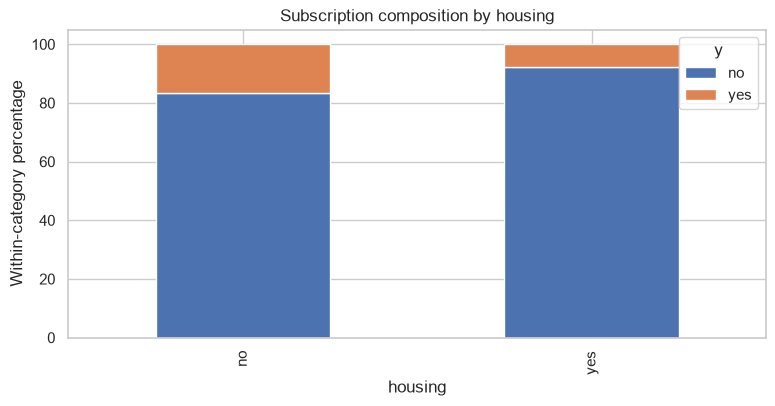

y,no,yes
loan,,
no,87.3,12.7
yes,93.3,6.7


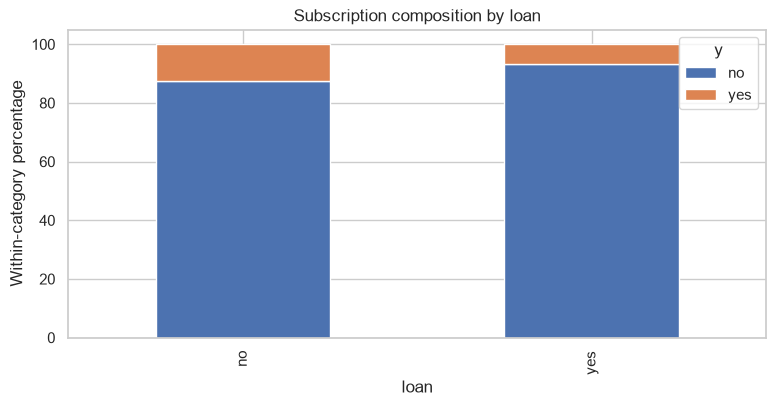

y,no,yes
marital,,
single,85.1,14.9
divorced,88.1,11.9
married,89.9,10.1


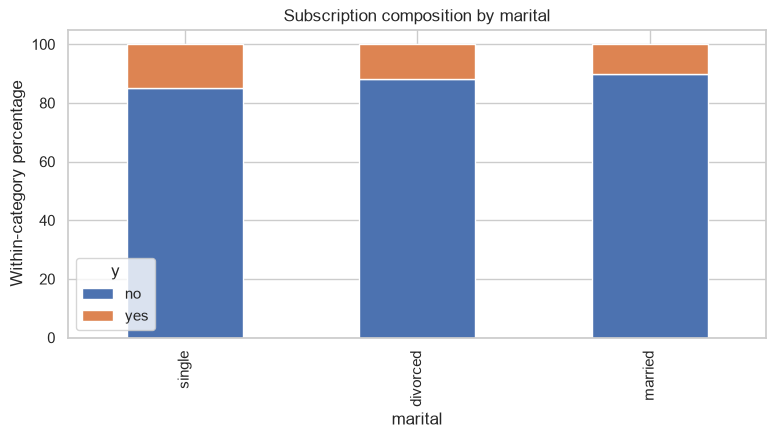

In [8]:
for col in [c for c in ["job", "education", "housing", "loan", "marital"] if c in df_clean.columns]:
    rates = pd.crosstab(df_clean[col], df_clean["y"], normalize="index") * 100
    if "yes" in rates.columns:
        rates = rates.sort_values("yes", ascending=False)
    display(rates.round(1))
    rates.plot(kind="bar", stacked=True, figsize=(9, 4))
    plt.title(f"Subscription composition by {col}")
    plt.ylabel("Within-category percentage")
    plt.show()

**Analysis prompt:** Compare within-category yes percentages. Mention any
categories with small counts. These are observed associations, not causal effects.

## 10. Multivariate EDA: numeric correlation

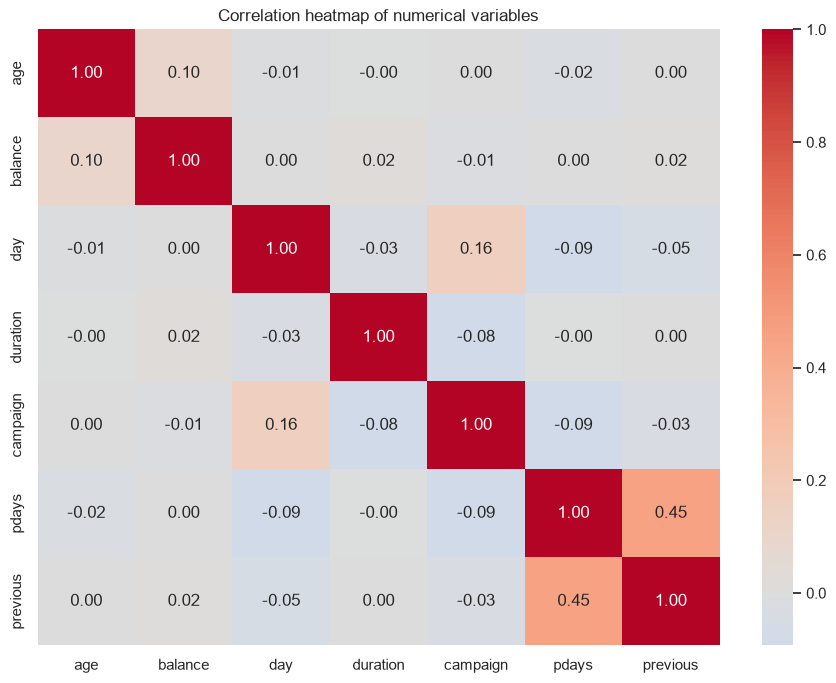

In [9]:
numeric_df = df_clean.select_dtypes(include=np.number)
plt.figure(figsize=(11, 8))
sns.heatmap(numeric_df.corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Correlation heatmap of numerical variables")
plt.show()

**Analysis prompt:** Identify the strongest positive and negative correlations
in the displayed heatmap. Explain that correlation measures pairwise linear
association and does not establish causation.

## 11. Statistical test 1 — Chi-square test of independence

In [10]:
job_table = pd.crosstab(df_clean["job"], df_clean["y"])
chi2, p_value, dof, expected = chi2_contingency(job_table)
n = job_table.to_numpy().sum()
r, k = job_table.shape
cramers_v = np.sqrt(chi2 / (n * min(r - 1, k - 1)))
print({"chi_square": chi2, "degrees_of_freedom": dof,
       "p_value": p_value, "cramers_v": cramers_v})
display(job_table)

{'chi_square': np.float64(836.1448351240688), 'degrees_of_freedom': 10, 'p_value': np.float64(3.486711140869683e-173), 'cramers_v': np.float64(0.1364289008309765)}


y,no,yes
job,,
admin.,4540,631
blue-collar,9024,708
entrepreneur,1364,123
housemaid,1131,109
management,8157,1301
retired,1748,516
self-employed,1392,187
services,3785,369
student,669,269


**Hypotheses:** H0: job category and subscription are independent. H1: they are
associated. Report chi-square, df, p-value and Cramér's V. A small p-value is
evidence against independence under assumptions; Cramér's V helps describe
association strength. Do not claim causation.

## 12. Statistical test 2 — Mann–Whitney U

In [11]:
yes_balance = df_clean.loc[df_clean["y"] == "yes", "balance"].dropna()
no_balance = df_clean.loc[df_clean["y"] == "no", "balance"].dropna()
u_stat, p_mw = mannwhitneyu(yes_balance, no_balance, alternative="two-sided")
print({
    "U_statistic": u_stat,
    "p_value": p_mw,
    "median_balance_yes": yes_balance.median(),
    "median_balance_no": no_balance.median()
})

{'U_statistic': np.float64(124589983.5), 'p_value': np.float64(6.593845808689515e-101), 'median_balance_yes': np.float64(733.0), 'median_balance_no': np.float64(417.0)}


**Hypotheses:** H0: the balance distributions are the same in the two independent
groups. H1: they differ. Report U, p-value and medians. Explain that the test
compares rank distributions and does not itself measure a causal effect.

## 13. Define prediction-time features and target

In [12]:
# Exclude duration: it is only known after the call and leaks post-call information.
X = df_clean.drop(columns=["y", "duration"], errors="ignore")
y = (df_clean["y"] == "yes").astype(int)
print("Predictor count used:", X.shape[1])
print("Target proportions:")
display(y.value_counts(normalize=True).rename("proportion"))

Predictor count used: 15
Target proportions:


y
0    0.883015
1    0.116985
Name: proportion, dtype: float64

**Analysis prompt:** Explain why excluding `duration` makes the task a realistic
pre-call prediction. The resulting predictor count is lower than the original
16 because one predictor is intentionally excluded.

## 14. Leakage-safe train/test split and preprocessing

In [13]:
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
num_features = X.select_dtypes(include=np.number).columns.tolist()
cat_features = [c for c in X.columns if c not in num_features]

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipe, num_features),
    ("cat", categorical_pipe, cat_features)
])
print("Train shape:", X_train.shape, "Test shape:", X_test.shape)
print("Numeric features:", num_features)
print("Categorical features:", cat_features)

Train shape: (36168, 15) Test shape: (9043, 15)
Numeric features: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


**Analysis prompt:** Explain 80:20 stratified split, median/mode imputation,
scaling, one-hot encoding and why preprocessing is inside a Pipeline. The test
set must not influence preprocessing, tuning or model selection.

## 15. Model comparison

In [14]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, f1_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
model_specs = {
    "Dummy baseline": (DummyClassifier(strategy="most_frequent"), {}),
    "Logistic Regression": (LogisticRegression(max_iter=1500, class_weight="balanced", solver="liblinear"),
                            {"model__C": [0.1, 1.0, 5.0]}),
    "Decision Tree": (DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
                      {"model__max_depth": [5, 10, None], "model__min_samples_leaf": [5, 20]}),
    "Random Forest": (RandomForestClassifier(n_estimators=250, class_weight="balanced_subsample",
                                              random_state=RANDOM_STATE, n_jobs=-1),
                      {"model__max_depth": [12, None], "model__min_samples_leaf": [2, 5],
                       "model__max_features": ["sqrt"]}),
    "HistGradientBoosting": (HistGradientBoostingClassifier(random_state=RANDOM_STATE),
                             {"model__learning_rate": [0.05, 0.1], "model__max_iter": [100, 180],
                              "model__max_leaf_nodes": [15, 31]})
}

The end-to-end `src/train.py` script performs the complete tuning and saves the
authoritative comparison in `outputs/model_comparison_cv.csv`. Run that script
for the official model comparison and held-out evaluation. This notebook section
defines the same model lineup for explanation; do not select a model based on
test-set results.

## 16. Read the official pipeline results after running `src/train.py`

In [15]:
comparison_path = OUT / "model_comparison_cv.csv"
metrics_path = OUT / "final_test_metrics.json"
if comparison_path.exists():
    display(pd.read_csv(comparison_path))
else:
    print("Run: python src/train.py — then rerun this cell.")
if metrics_path.exists():
    metrics = json.loads(metrics_path.read_text(encoding="utf-8"))
    display(pd.Series({k: metrics.get(k) for k in [
        "selected_model", "accuracy", "precision", "recall", "f1",
        "roc_auc", "pr_auc_average_precision"
    ]}))
else:
    print("Final metrics will appear after the end-to-end script completes.")

,model,cv_f1,best_parameters
0,Random Forest,0.460754,"{""model__max_depth"": null, ""model__max_feature..."
1,Decision Tree,0.388875,"{""model__max_depth"": 10, ""model__min_samples_l..."
2,Logistic Regression,0.365374,"{""model__C"": 1.0}"
3,HistGradientBoosting,0.332499,"{""model__learning_rate"": 0.1, ""model__max_iter..."
4,Dummy baseline,0.000000,"{""strategy"": ""most_frequent""}"


selected_model              Random Forest
accuracy                         0.868075
precision                         0.44389
recall                           0.504726
f1                               0.472357
roc_auc                          0.791053
pr_auc_average_precision         0.446643
dtype: object

## 17. Final evaluation and business interpretation

Use the actual values in `final_test_metrics.json` and inspect:
- `03_confusion_matrix.png`
- `04_roc_curve.png`
- `05_precision_recall_curve.png`

Explain precision, recall, F1, ROC-AUC and PR-AUC. Discuss false positives
(outreach to customers who do not subscribe) and false negatives (missed potential
subscribers). The preferred trade-off depends on campaign costs and capacity.

## 18. Feature interpretation

In [16]:
importance_path = OUT / "permutation_importance.csv"
if importance_path.exists():
    importance = pd.read_csv(importance_path)
    display(importance.head(15))
else:
    print("Run src/train.py first to generate permutation_importance.csv.")

,feature,importance_mean,importance_std
0,month,0.095087,0.002451
1,poutcome,0.048907,0.004131
2,housing,0.043332,0.004846
3,day,0.024285,0.002829
4,age,0.013908,0.002277
5,pdays,0.010027,0.001916
6,balance,0.008861,0.006533
7,campaign,0.007397,0.002715
8,loan,0.006495,0.003265
9,marital,0.003399,0.002403


**Interpretation:** Permutation importance measures how much the fitted model's
F1 decreases when a feature is shuffled. It is model-specific, can be affected by
correlated features, and is not evidence that a feature causes subscription.

## 19. Conclusion worksheet

Complete after inspecting your actual output:

- Best model selected by training-only CV F1: **[actual model]**
- Held-out test F1 / recall / precision / ROC-AUC / PR-AUC: **[actual values]**
- Most useful features according to permutation importance: **[actual features]**
- Main EDA insight: **[what your plots show]**
- Statistical test interpretation: **[actual statistics and effect size]**
- Main limitations: historical/institution-specific data, class imbalance,
  possible temporal drift, unknown categories, no causal inference, no external validation.
- Improvement: evaluate on newer independent data, calibrate probabilities and
  select a decision threshold using validation data and business costs.